# Hebrew real / synthetic voice distributions — multiple views

This notebook analyzes **actual ECAPA embeddings**, acoustic features, nominal identity consistency and coverage. No inference download or paid API request occurs in notebook execution; cached embeddings are required. The local CPU extraction is in `ecapa_embeddings.py`. See `VOICE_DISTRIBUTION_PLAN.md` for prespecified analyses and `VOICE_DISTRIBUTIONS_REPORT_HE.md` for Hebrew results.

Scope: up to three 3–8 s excerpts per qualified real speaker, preferring distinct sessions/texts, versus all stock synthetic clips. Selection targets identity coverage, not corpus-hour or population representation. Five real IDs have no eligible excerpt under these criteria; keep them in the audit. There are no human-verified new labels. Synthetic samples read one text while real samples vary; text/phonetics, native codec and boundaries remain confounders.

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
from IPython.display import display, Image
import analyze_voice_distributions as analysis
ROOT=Path.cwd(); OUT=ROOT/'voice_distribution'
metrics=analysis.main()
def table(name): return pd.read_csv(OUT/(name+'.csv'))
def figure(name): display(Image(filename=str(OUT/'figures'/(name+'.png'))))
samples=table('samples')
display(pd.Series(metrics,name='value').to_frame())
display(samples.groupby('label').agg(clips=('sample_id','size'),identities=('group_id','nunique'),seconds=('duration_s','sum')))


C:\Users\amitn\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py:136: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] The system cannot find the file specified
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "C:\Users\amitn\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
               ^^^^^^^^^^^^^^^
  File "C:\Users\amitn\anaconda3\Lib\subprocess.py", line 548, in run
    with Popen(*popenargs, **kwargs) as process:
         ^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "C:\Users\amitn\anaconda3\Lib\subprocess.py", line 1026, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
  File "C:\Users\amitn\anaconda3\Lib\subprocess.py", line 1538, in _execute_child
    hp, ht, pid, tid = _winapi.CreatePro

,value
original_real_same_identity_pair_auc,0.996716
original_real_cross_session_pair_auc,0.996318
real_cross_session_positive_pairs,200.000000
real_cross_session_supported_speakers,69.000000
original_synthetic_same_identity_pair_auc,0.989500
pca_2d_variance_fraction,0.124401
edge_trimmed_real_same_identity_pair_auc,0.996726
edge_trimmed_real_cross_session_pair_auc,0.996331
edge_trimmed_synthetic_same_identity_pair_auc,0.988519
real_clips,231.000000


,clips,identities,seconds
label,,,
real,231,80,1023.300
synthetic,284,116,1326.811


## 1. Selection, extraction and technical provenance

Real selection requires source/alignment scores >=0.8, 3–8 s, 6–14 words and positive in-bounds timing. Different sessions and normalized texts are preferred, then duration near 4.5 s. This does not validate speaker identity or transcript by listening.

Initial timestamp-addressed slicing exposed jittered MKA packet clocks. Inserting zeros at every packet gap would create artificial silence. The final extraction therefore uses concatenated decoded sample counts, consistent with prior EDA. Initial attempt records remain separate and must not be interpreted as source audio failures. No attempt was made to repair actual clock discontinuities; listening/boundary validation remains pending.

Official SpeechBrain Fbank (80 mel bins), sentence mean normalization and pretrained ECAPA layers output 192 dimensions. We use strict weight loading, no speaker classifier or gender/age model, and L2-normalize each vector. Global speaker-verification thresholds and VoxCeleb benchmark scores are not transferred to this Hebrew dataset.

In [2]:
coverage=table('real_speaker_coverage')
display(coverage.describe())
display(coverage.loc[coverage.extracted.eq(0)])
display(json.loads((OUT/'model_provenance.json').read_text()))
display(json.loads((OUT/'inference_environment.json').read_text()))
display(samples.loc[samples.label.eq('real')].groupby('sex_label').agg(speakers=('group_id','nunique'),clips=('sample_id','size')))
display(samples.loc[samples.label.eq('real')].groupby('age_proxy_bin').agg(speakers=('group_id','nunique'),clips=('sample_id','size')))


,eligible_candidates,selected,extracted,distinct_selected_sessions
count,85.000000,85.000000,85.000000,85.000000
mean,164.011765,2.717647,2.717647,2.482353
std,227.312062,0.810816,0.810816,0.933653
min,0.000000,0.000000,0.000000,0.000000
25%,10.000000,3.000000,3.000000,2.000000
50%,38.000000,3.000000,3.000000,3.000000
75%,278.000000,3.000000,3.000000,3.000000
max,760.000000,3.000000,3.000000,3.000000


,user_id,eligible_candidates,selected,extracted,distinct_selected_sessions
32,72063563-00ed-4c5a-84f7-1b55b009071a,0,0,0,0
65,c88f6064-5a8c-4f31-954e-414c843c9c2b,0,0,0,0
69,d1d5a9d7-0133-4fff-83ce-0db936d6367c,0,0,0,0
70,d5af59c6-3e96-45e3-bf7a-7b311b5213f1,0,0,0,0
74,dd44d324-b44f-4fb4-a7ca-b2c6ae8c6873,0,0,0,0


{'repo': 'speechbrain/spkrec-ecapa-voxceleb',
 'revision': '0f99f2d0ebe89ac095bcc5903c4dd8f72b367286',
 'files': {'embedding_model.ckpt': '0575cb64845e6b9a10db9bcb74d5ac32b326b8dc90352671d345e2ee3d0126a2',
  'hyperparams.yaml': '6f78854fa04ba59e761437b76a2575d3aba5e5016de3e9b69f0c9a5077fb1a41'}}

{'versions': {'torch': '2.8.0+cpu',
  'torchaudio': '2.8.0+cpu',
  'speechbrain': '1.1.2',
  'numpy': '1.26.4',
  'huggingface-hub': '1.24.0'},
 'device': 'cpu',
 'torch_threads': 4,
 'seconds': 423.9801621437073,
 'embedding_normalization': 'L2 after encode, official encode_batch normalize=False equivalent; sentence mean normalization, no classifier or global embedding normalization',
 'model_state_strict_load': True,
 'views': ['original', 'edge_trimmed'],
 'cached_entries_at_start': 0}

,speakers,clips
sex_label,,
female,25,71
male,43,124
unknown,12,36


,speakers,clips
age_proxy_bin,,
0-17,1,3
18-29,7,21
30-39,23,69
40-49,13,38
50-59,10,28
60-69,4,10
unknown,22,62


## 2. Hebrew sanity check: same real identity versus different identity

Compare cosine distributions among the sampled real clips. Separately report same-speaker pairs from different sessions, because shared microphones/session conditions can inflate same-session agreement. Different-speaker negative pairs include the observed recording-condition mix. Pairs are dependent; AUC is an exploratory same-ID ranking statistic on this sample, **not deepfake detector performance or a validated identity threshold**.

Some real IDs have only one eligible clip. Within-identity claims apply only where repeated clips exist. Strong separation supports local utility of the representation; it does not establish unbiased Hebrew speaker verification.

,view,label,comparison,n,mean,median,p05,p95
0,original,real,same_group,226,0.632984,0.648969,0.422442,0.777583
1,original,real,different_group,26339,0.115498,0.108712,-0.023793,0.280081
2,original,real,same_group_cross_session,200,0.627902,0.645281,0.413543,0.775781
5,original,real,different_group_centroids,3160,0.151615,0.142800,0.006568,0.331574
7,edge_trimmed,real,same_group,226,0.633291,0.646761,0.430232,0.778015
8,edge_trimmed,real,different_group,26339,0.115281,0.108373,-0.023841,0.279807
9,edge_trimmed,real,same_group_cross_session,200,0.628350,0.644728,0.413543,0.777421
12,edge_trimmed,real,different_group_centroids,3160,0.151289,0.142598,0.006818,0.330361


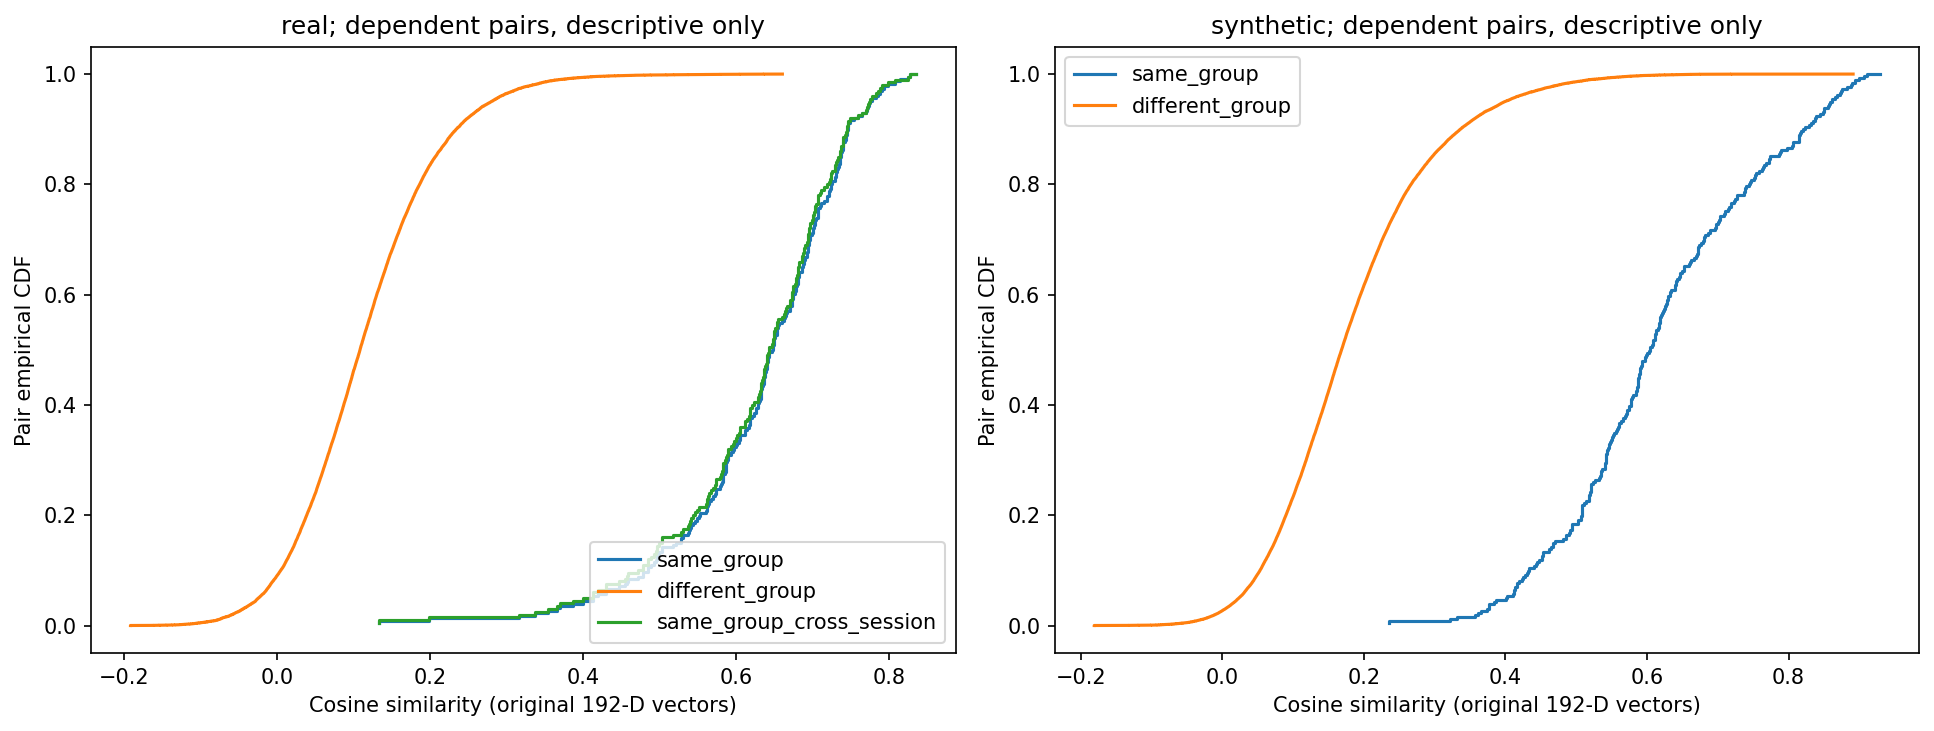

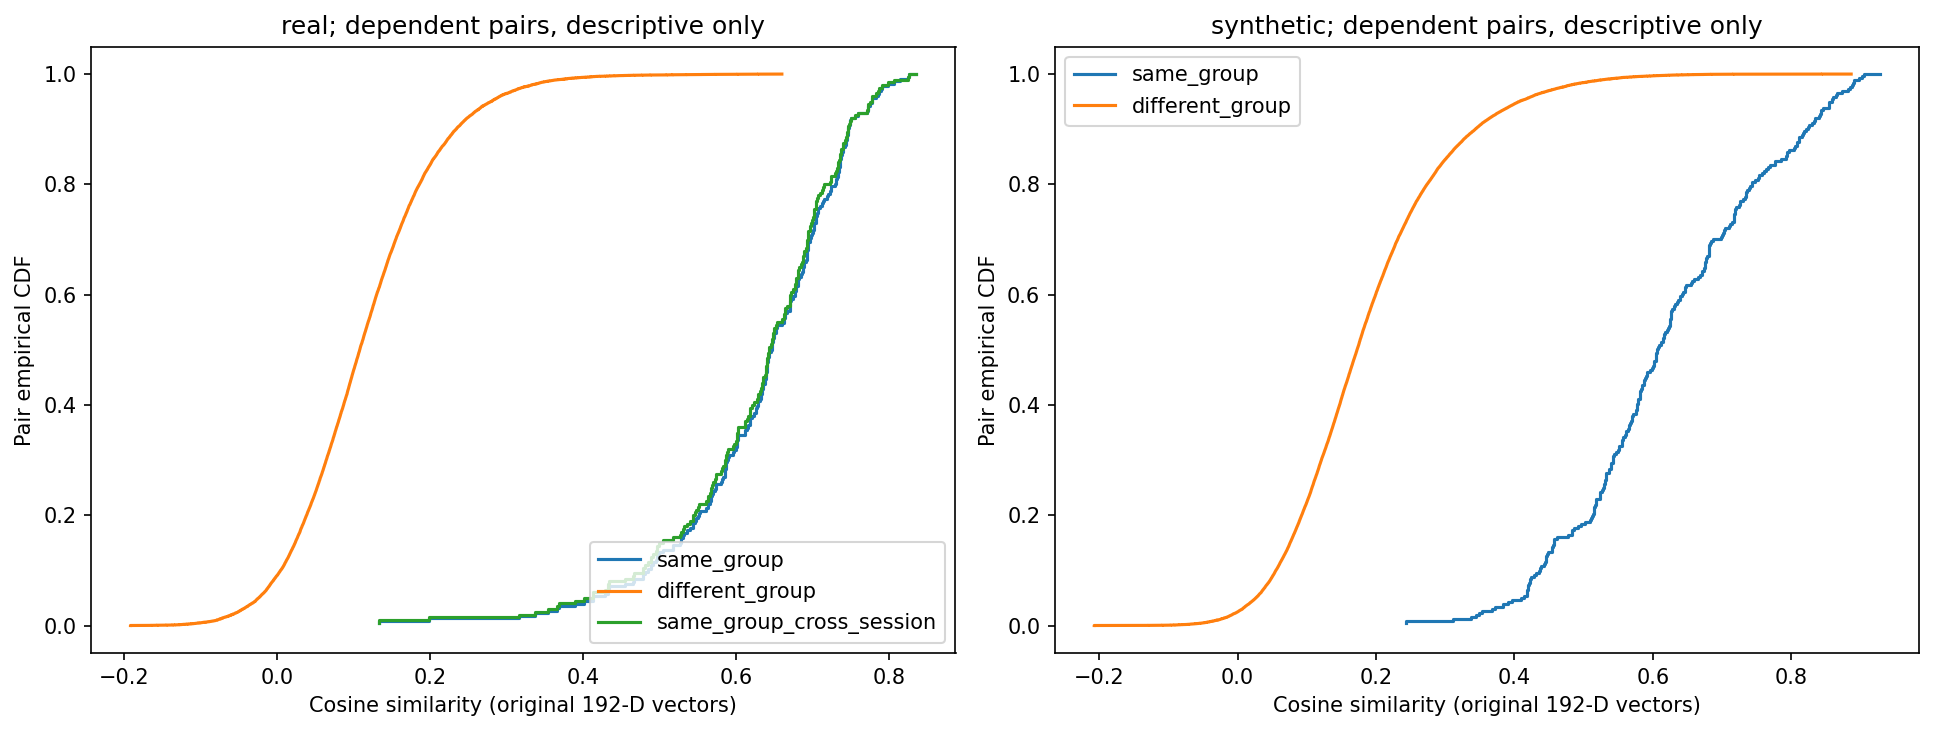

original_real_same_identity_pair_auc               0.996716
original_real_cross_session_pair_auc               0.996318
real_cross_session_positive_pairs                200.000000
real_cross_session_supported_speakers             69.000000
original_synthetic_same_identity_pair_auc          0.989500
edge_trimmed_real_same_identity_pair_auc           0.996726
edge_trimmed_real_cross_session_pair_auc           0.996331
edge_trimmed_synthetic_same_identity_pair_auc      0.988519
dtype: float64

In [3]:
summary=table('cosine_distribution_summary')
display(summary.loc[summary.label.eq('real')])
figure('identity_consistency_original')
figure('identity_consistency_edge_trimmed')
display(pd.Series({k:v for k,v in metrics.items() if 'auc' in k or 'cross_session' in k}))


## 3. Synthetic consistency, diversity and listening candidates

A nominal provider:voice may occur in two to four model versions. Compare these pairs with different-voice pairs, and inspect both low-consistency same-name groups and high-similarity different-name groups. These are **listening candidates, not duplicate or identity proof**. Content is the same for every synthetic clip, which may itself elevate similarities. Cross-provider voices can also share origins unknown to us.

Centroids are L2-normalized means of L2 vectors. Each nominal identity gets one centroid regardless of its number of versions. This is a conservative grouping, not a biometric identity declaration.

In [4]:
display(summary.loc[summary.label.eq('synthetic')])
within=table('within_identity_pairs')
display(within.loc[within.label.eq('synthetic')].sort_values('cosine_similarity').head(16))
display(table('closest_synthetic_groups_original').head(15))
display(table('closest_real_groups_original').head(10))


,view,label,comparison,n,mean,median,p05,p95
3,original,synthetic,same_group,261,0.618234,0.603961,0.411068,0.861108
4,original,synthetic,different_group,39925,0.183352,0.168369,0.023517,0.399025
6,original,synthetic,different_group_centroids,6670,0.212868,0.194538,0.039067,0.452512
10,edge_trimmed,synthetic,same_group,261,0.621810,0.607303,0.417553,0.858146
11,edge_trimmed,synthetic,different_group,39925,0.187683,0.172478,0.026205,0.406682
13,edge_trimmed,synthetic,different_group_centroids,6670,0.218070,0.199552,0.045108,0.463029


,view,label,group_id,sample_a,sample_b,model_a,model_b,cross_session,cosine_similarity
303,original,synthetic,google:Rasalgethi,e3afb09fcb4d01ac75a1,945852d1b2fb02be224d,google/gemini-3.8-flash-tts,google/gemini-3.1-flash-tts-preview,True,0.234888
790,edge_trimmed,synthetic,google:Rasalgethi,e3afb09fcb4d01ac75a1,945852d1b2fb02be224d,google/gemini-3.8-flash-tts,google/gemini-3.1-flash-tts-preview,True,0.242840
754,edge_trimmed,synthetic,google:Alnilam,573a9b9c280e7e064706,07bf912c84088d9145de,google/gemini-3.8-flash-lite-tts,google/gemini-3.1-flash-tts-preview,True,0.310826
267,original,synthetic,google:Alnilam,573a9b9c280e7e064706,07bf912c84088d9145de,google/gemini-3.8-flash-lite-tts,google/gemini-3.1-flash-tts-preview,True,0.320909
261,original,synthetic,google:Rasalgethi,d73dc5d47d8fc3e89e65,945852d1b2fb02be224d,google/gemini-3.8-flash-lite-tts,google/gemini-3.1-flash-tts-preview,True,0.330808
748,edge_trimmed,synthetic,google:Rasalgethi,d73dc5d47d8fc3e89e65,945852d1b2fb02be224d,google/gemini-3.8-flash-lite-tts,google/gemini-3.1-flash-tts-preview,True,0.336650
837,edge_trimmed,synthetic,elevenlabs:eric,c4cfe1cd966ed67ec6a7,42b6cf981727df330336,elevenlabs/eleven-v3,elevenlabs/eleven-v4,True,0.344385
838,edge_trimmed,synthetic,elevenlabs:eric,c4cfe1cd966ed67ec6a7,19d1358e61c03307e839,elevenlabs/eleven-v3,elevenlabs/eleven-v4-turbo,True,0.349037
804,edge_trimmed,synthetic,elevenlabs:george,31b63dc01858e0bb0533,0fec59e628f6a279765d,elevenlabs/eleven-v3,elevenlabs/eleven-v4,True,0.352417
350,original,synthetic,elevenlabs:eric,c4cfe1cd966ed67ec6a7,42b6cf981727df330336,elevenlabs/eleven-v3,elevenlabs/eleven-v4,True,0.357353


,group_a,group_b,family_a,family_b,cosine_similarity,status
0,minimax:English_Upbeat_Woman,minimax:English_captivating_female1,minimax,minimax,0.892280,listen_candidate_not_duplicate_proof
1,google:Leda,google:Sulafat,google,google,0.784674,listen_candidate_not_duplicate_proof
2,minimax:English_ConfidentWoman,minimax:English_PlayfulGirl,minimax,minimax,0.752763,listen_candidate_not_duplicate_proof
3,google:Erinome,google:Laomedeia,google,google,0.741167,listen_candidate_not_duplicate_proof
4,minimax:English_SereneWoman,minimax:English_WhimsicalGirl,minimax,minimax,0.731822,listen_candidate_not_duplicate_proof
5,minimax:English_ConfidentWoman,minimax:English_SereneWoman,minimax,minimax,0.731322,listen_candidate_not_duplicate_proof
6,google:Autonoe,google:Kore,google,google,0.728791,listen_candidate_not_duplicate_proof
7,minimax:English_PlayfulGirl,minimax:English_SereneWoman,minimax,minimax,0.719582,listen_candidate_not_duplicate_proof
8,minimax:English_ConfidentWoman,minimax:English_WhimsicalGirl,minimax,minimax,0.701712,listen_candidate_not_duplicate_proof
9,elevenlabs:matilda,google:Autonoe,elevenlabs,google,0.698267,listen_candidate_not_duplicate_proof


,group_a,group_b,family_a,family_b,cosine_similarity,status
0,224a4c01-03cf-4b12-9d8c-15c72591143e,f6f9de3c-13b4-42aa-9f44-b3459bed4c7d,real,real,0.764029,listen_candidate_not_duplicate_proof
1,efd5eafb-a71a-456d-b7f4-27ffa78cabf3,f6f9de3c-13b4-42aa-9f44-b3459bed4c7d,real,real,0.672778,listen_candidate_not_duplicate_proof
2,ba874f1e-4237-420f-9520-dc69403d2f8b,f6f9de3c-13b4-42aa-9f44-b3459bed4c7d,real,real,0.669553,listen_candidate_not_duplicate_proof
3,224a4c01-03cf-4b12-9d8c-15c72591143e,efd5eafb-a71a-456d-b7f4-27ffa78cabf3,real,real,0.646459,listen_candidate_not_duplicate_proof
4,ba874f1e-4237-420f-9520-dc69403d2f8b,efd5eafb-a71a-456d-b7f4-27ffa78cabf3,real,real,0.633586,listen_candidate_not_duplicate_proof
5,224a4c01-03cf-4b12-9d8c-15c72591143e,ba874f1e-4237-420f-9520-dc69403d2f8b,real,real,0.630376,listen_candidate_not_duplicate_proof
6,021c1fbf-05c6-4a5c-9f8c-89b510a86a83,efd5eafb-a71a-456d-b7f4-27ffa78cabf3,real,real,0.573112,listen_candidate_not_duplicate_proof
7,487c518c-61a4-41d8-9cab-bb075e317037,a92cf0d3-4b56-485c-9181-e7df3304c9d8,real,real,0.552674,listen_candidate_not_duplicate_proof
8,487c518c-61a4-41d8-9cab-bb075e317037,a6d23969-9763-485b-bbfc-28a9c0ea78b0,real,real,0.550018,listen_candidate_not_duplicate_proof
9,04d374d1-9317-4cf1-9961-158385f3f9f0,98e51ba2-4388-48c6-b591-69d357352539,real,real,0.510764,listen_candidate_not_duplicate_proof


## 4. Shared PCA and t-SNE maps

Both groups are projected together using one centroid per identity, coloured by real/family. PCA reports retained variance; t-SNE uses a fixed seed and perplexity 30. Plots may reveal local clusters/provider effects, but apparent overlap/separation is not a hypothesis test. All reported cosine/kernel metrics use the full original 192-dimensional space.

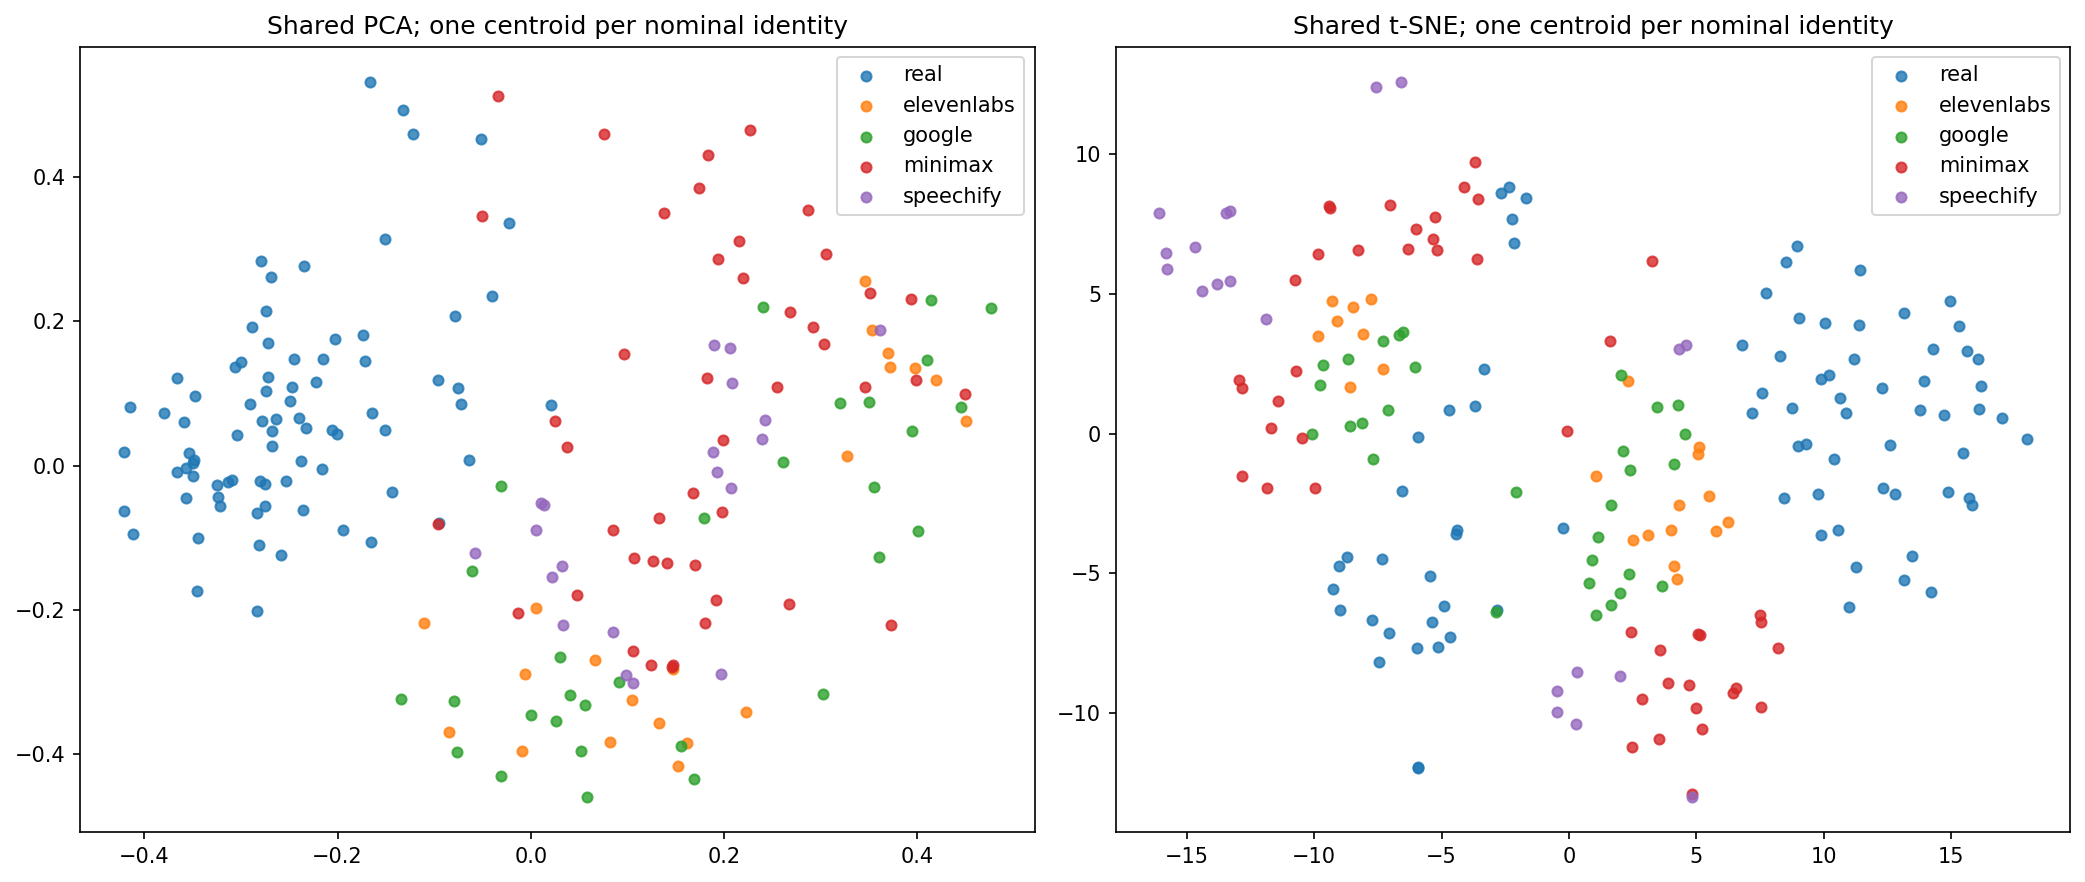

Fraction of variance retained by 2-D PCA: 0.1244005411863327


,label,group_id,family,clips,sex_label,age_proxy_bin,pca1,pca2,tsne1,tsne2
0,real,0085e975-881a-4775-b437-c8fb97f7bf81,real,3,unknown,unknown,-0.283635,-0.200882,7.183330,0.733535
1,real,021c1fbf-05c6-4a5c-9f8c-89b510a86a83,real,3,unknown,unknown,-0.022509,0.337156,-2.151104,6.832792
2,real,04d374d1-9317-4cf1-9961-158385f3f9f0,real,3,unknown,unknown,-0.322106,-0.055805,15.623146,2.963827
3,real,10fb2bc7-dcf8-48e2-86d6-088a56abfb54,real,3,male,30-39,-0.288964,0.191922,11.379161,3.893185
4,real,1184cab7-edc8-4139-ac5b-e2ce5fb72963,real,3,female,40-49,0.020650,0.084512,-5.939011,-0.113465


In [5]:
figure('speaker_projections')
print('Fraction of variance retained by 2-D PCA:',metrics['pca_2d_variance_fraction'])
display(table('projection_coordinates').head())


## 5. Coverage: nearest acoustic neighbours

Compare real-to-synthetic and synthetic-to-real nearest centroid distances, with a within-real reference. Candidate sets differ in size, so nearest-distance differences alone cannot establish better coverage. Nearest synthetic identity for a real speaker is an acoustic neighbour, not a cloned identity or prescribed matching assignment.

Do not select only nearest neighbours to create the main dataset: that changes the target to similar-sounding voices and may discard legitimate diversity. Use these candidates to find uncovered regions and for a separate controlled sensitivity subset.

count    median       min       max
view         direction                                                    
edge_trimmed real_to_other_class          80  0.680097  0.301923  0.815675
             synthetic_to_other_class    116  0.679981  0.301923  0.848260
original     real_to_other_class          80  0.675436  0.297910  0.817879
             synthetic_to_other_class    116  0.685266  0.297910  0.862909

,view,direction,group_id,family,nearest_group,nearest_family,cosine_similarity,cosine_distance,meaning
36,original,real_to_other_class,7f17b3a7-9839-4bef-a140-4d53df436501,real,minimax:English_CalmWoman,minimax,0.182121,0.817879,candidate_acoustic_neighbour_not_identity_or_d...
49,original,real_to_other_class,aef160e6-2ba5-4015-a2aa-15f433181cc6,real,minimax:English_ManWithDeepVoice,minimax,0.214701,0.785299,candidate_acoustic_neighbour_not_identity_or_d...
3,original,real_to_other_class,10fb2bc7-dcf8-48e2-86d6-088a56abfb54,real,elevenlabs:liam,elevenlabs,0.228936,0.771064,candidate_acoustic_neighbour_not_identity_or_d...
7,original,real_to_other_class,20c0ff8b-be92-4110-8793-6de3904e4c14,real,elevenlabs:liam,elevenlabs,0.230247,0.769753,candidate_acoustic_neighbour_not_identity_or_d...
26,original,real_to_other_class,5bf9ce6e-8c60-4214-91b3-77ac7a8857b0,real,elevenlabs:river,elevenlabs,0.240332,0.759668,candidate_acoustic_neighbour_not_identity_or_d...
58,original,real_to_other_class,c096e3be-cb3c-4147-aaa2-09f9e69f7079,real,minimax:English_Kind-heartedGirl,minimax,0.242025,0.757975,candidate_acoustic_neighbour_not_identity_or_d...
20,original,real_to_other_class,46520d94-710b-44b5-bcef-e8ffbb427e9c,real,google:Achird,google,0.244137,0.755863,candidate_acoustic_neighbour_not_identity_or_d...
9,original,real_to_other_class,27129c7f-1195-4f7c-9406-ccadec96223d,real,google:Vindemiatrix,google,0.244664,0.755336,candidate_acoustic_neighbour_not_identity_or_d...
44,original,real_to_other_class,a1236536-8f5d-4eb7-a2e6-0344a6f3e279,real,google:Alnilam,google,0.246858,0.753142,candidate_acoustic_neighbour_not_identity_or_d...
21,original,real_to_other_class,4802f33e-3098-43ab-91d4-465ddbf7c44c,real,elevenlabs:liam,elevenlabs,0.247692,0.752308,candidate_acoustic_neighbour_not_identity_or_d...


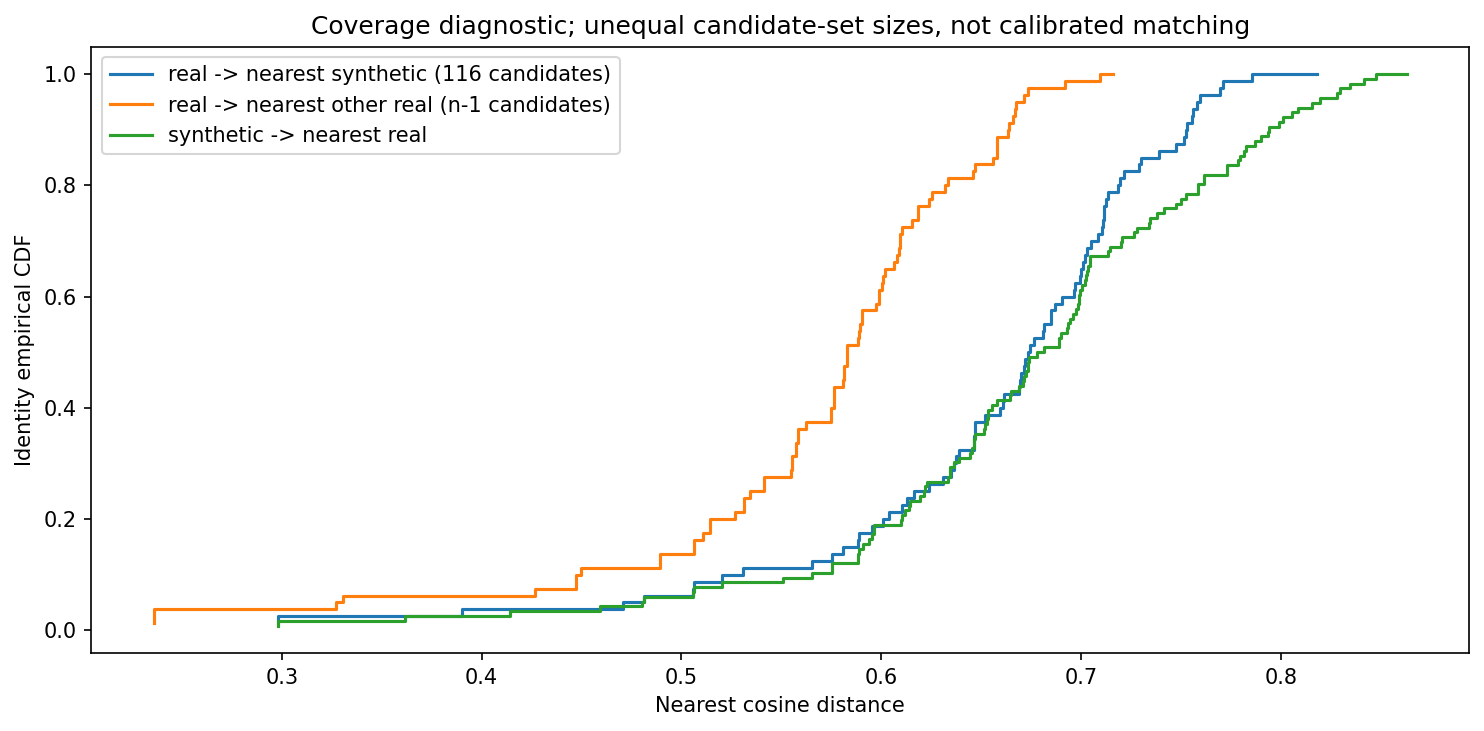

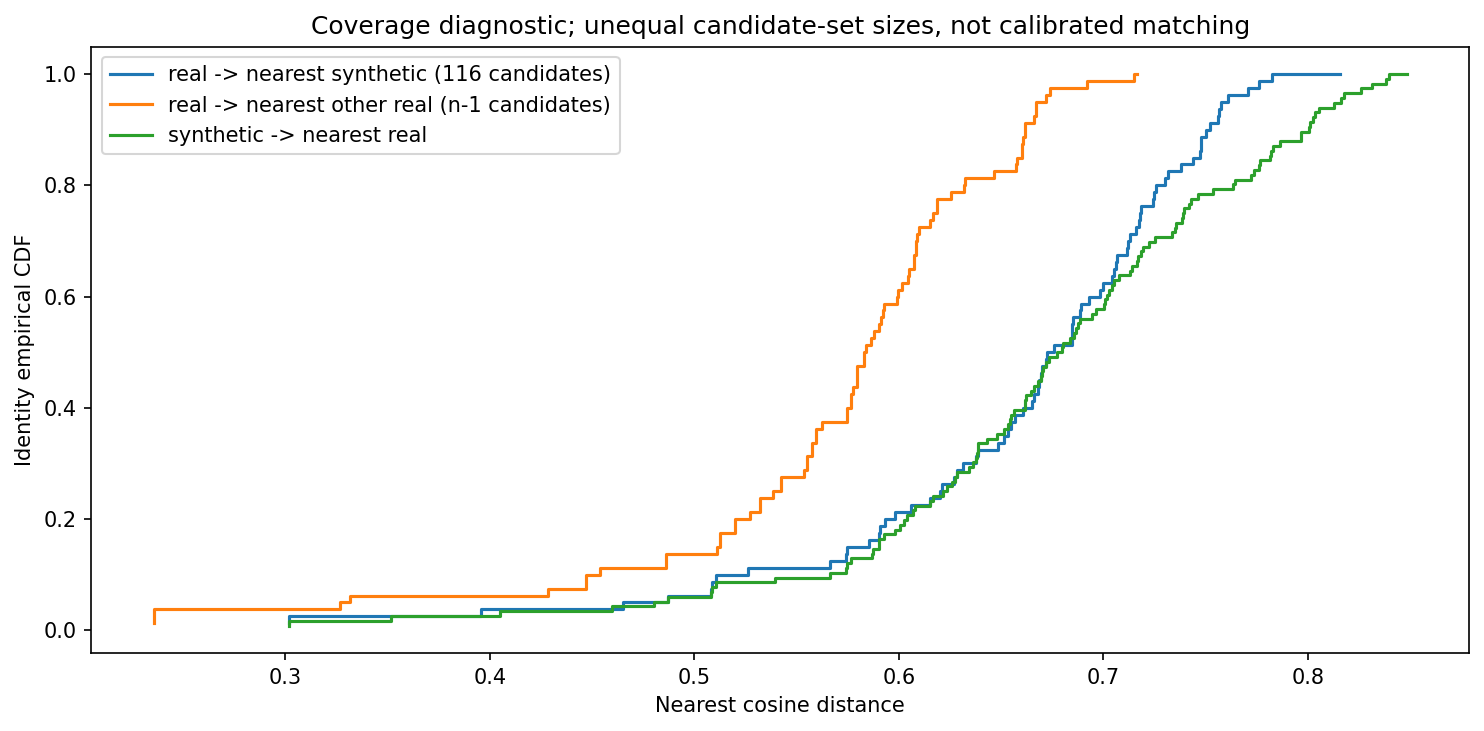

In [6]:
neighbours=table('cross_class_nearest_neighbours')
display(neighbours.groupby(['view','direction']).cosine_distance.agg(['count','median','min','max']))
display(neighbours.loc[(neighbours.view=='original')&(neighbours.direction=='real_to_other_class')].sort_values('cosine_distance',ascending=False).head(12))
figure('nearest_coverage_original')
figure('nearest_coverage_edge_trimmed')


## 6. Kernel distribution distance and family weighting

Biased weighted RBF MMD squared compares identity-centroid distributions at 0.5x, 1x and 2x the pooled median squared-distance bandwidth scale. Lower means closer under that representation/kernel; it is **not a percentage of realism or a universal quality score**. Finite sample sizes and domain effects matter. Report both equal-identity and equal-family weights.

For family comparisons, sample the same number of real and synthetic identities per family comparison (up to 20 each), repeat 200 times and report the observed composition range. Those ranges are not confidence intervals for a population, significance tests or causal synthesis effects.

In [7]:
display(table('kernel_distribution_distances'))
display(table('equal_size_family_sensitivity'))
display(table('equal_size_family_coverage'))
display(table('one_clip_per_identity_sensitivity').groupby('view').agg({'mmd_squared_one_clip_per_identity':['median','min','max'],'median_between_real_cosine':'median','median_between_synthetic_cosine':'median'}))


,view,target,bandwidth_multiplier,pooled_median_squared_distance,biased_weighted_mmd_squared,real_groups,synthetic_groups
0,original,all_identity_equal,0.5,1.745049,0.095534,80,116
1,original,all_family_equal,0.5,1.745049,0.097816,80,116
2,original,elevenlabs,0.5,1.745049,0.164898,80,21
3,original,google,0.5,1.745049,0.145005,80,30
4,original,minimax,0.5,1.745049,0.117745,80,45
5,original,speechify,0.5,1.745049,0.151010,80,20
6,original,all_identity_equal,1.0,1.745049,0.074082,80,116
7,original,all_family_equal,1.0,1.745049,0.075825,80,116
8,original,elevenlabs,1.0,1.745049,0.121477,80,21
9,original,google,1.0,1.745049,0.106646,80,30


,view,family,groups_each,subsamples,median_mmd_squared,p025,p975,interpretation
0,original,elevenlabs,20,200,0.136306,0.126875,0.147770,observed_subset_composition_range_not_populati...
1,original,google,20,200,0.126781,0.112956,0.141648,observed_subset_composition_range_not_populati...
2,original,minimax,20,200,0.114748,0.100035,0.133278,observed_subset_composition_range_not_populati...
3,original,speechify,20,200,0.130327,0.121819,0.143053,observed_subset_composition_range_not_populati...
4,edge_trimmed,elevenlabs,20,200,0.136845,0.126142,0.148100,observed_subset_composition_range_not_populati...
5,edge_trimmed,google,20,200,0.129019,0.115448,0.141921,observed_subset_composition_range_not_populati...
6,edge_trimmed,minimax,20,200,0.118431,0.100395,0.137989,observed_subset_composition_range_not_populati...
7,edge_trimmed,speechify,20,200,0.132819,0.124490,0.144664,observed_subset_composition_range_not_populati...


,view,family,synthetic_candidates_each,real_groups,subsamples,median_real_nearest_distance,p025,p975,interpretation
0,original,elevenlabs,20,80,200,0.760470,0.757034,0.771829,same_candidate_count_descriptive_coverage_not_...
1,original,google,20,80,200,0.726581,0.712159,0.742526,same_candidate_count_descriptive_coverage_not_...
2,original,minimax,20,80,200,0.772808,0.762217,0.792036,same_candidate_count_descriptive_coverage_not_...
3,original,speechify,20,80,200,0.835699,0.835699,0.835699,same_candidate_count_descriptive_coverage_not_...
4,edge_trimmed,elevenlabs,20,80,200,0.758636,0.757227,0.766486,same_candidate_count_descriptive_coverage_not_...
5,edge_trimmed,google,20,80,200,0.725191,0.716720,0.742766,same_candidate_count_descriptive_coverage_not_...
6,edge_trimmed,minimax,20,80,200,0.779201,0.761578,0.797932,same_candidate_count_descriptive_coverage_not_...
7,edge_trimmed,speechify,20,80,200,0.835603,0.835603,0.835603,same_candidate_count_descriptive_coverage_not_...


mmd_squared_one_clip_per_identity                      \
                                        median       min       max   
view                                                                 
edge_trimmed                          0.061951  0.058314  0.064835   
original                              0.060088  0.057266  0.063612   

             median_between_real_cosine median_between_synthetic_cosine  
                                 median                          median  
view                                                                     
edge_trimmed                   0.108567                        0.162618  
original                       0.108983                        0.157801

## 7. Independent acoustic-feature view and practical limits

Recompute identical duration, level, absolute-energy quiet, edge and spectral features for all sampled audio. Use per-identity medians and pooled median/IQR scaling for a compact multivariate comparison. Scaling is for visualization, not a finalized preprocessing policy. These features are not SNR, human quality judgments, or demographic labels.

Interpret alongside prior native-unit effect tables and the corpus-level sex/age/time coverage audits. ECAPA does not replace those. If distribution differences persist after capped trim, that does not identify a synthesis artifact: text, recording conditions, language domain and sampling can still explain them.

,duration_s,rms_dbfs,quiet_fraction_45dbfs,edge_quiet_fraction,energy_dynamic_range_db,spectral_centroid_hz,highband_energy_fraction,spectral_flatness,zero_crossing_fraction
label,,,,,,,,,
real,4.50000,-22.468606,0.122502,0.000000,29.499217,462.934859,0.000569,0.001041,0.135717
synthetic,4.49475,-19.725194,0.176708,0.094569,44.606717,430.852036,0.001287,0.003895,0.124801


,view,feature,real_groups,synthetic_groups,real_median,synthetic_median,median_difference,mean_difference,smd,cliffs_delta,wasserstein_distance,bootstrap_mean_difference_low,bootstrap_mean_difference_high,in_sample_orientation_free_auc
0,selected_original,duration_s,80,116,4.500000,4.494750,-0.005250,0.186384,0.475443,0.149353,0.284427,0.091379,0.290878,0.574677
1,selected_original,rms_dbfs,80,116,-22.468606,-19.725194,2.743412,0.901292,0.223968,0.237069,1.946492,-0.242464,1.961480,0.618534
2,selected_original,quiet_fraction_45dbfs,80,116,0.122502,0.176708,0.054206,0.039765,0.640584,0.350862,0.040511,0.022253,0.057632,0.675431
3,selected_original,edge_quiet_fraction,80,116,0.000000,0.094569,0.094569,0.091496,3.637222,0.974353,0.091496,0.084189,0.098111,0.987177
4,selected_original,energy_dynamic_range_db,80,116,29.499217,44.606717,15.107500,9.362095,0.493113,0.520905,13.264615,3.325848,14.200630,0.760453
5,selected_original,spectral_centroid_hz,80,116,462.934859,430.852036,-32.082824,-25.991658,-0.219781,-0.106897,28.436180,-60.340716,7.346662,0.553448
6,selected_original,highband_energy_fraction,80,116,0.000569,0.001287,0.000718,0.000774,0.314866,0.399784,0.000819,0.000216,0.001502,0.699892
7,selected_original,spectral_flatness,80,116,0.001041,0.003895,0.002854,0.002650,0.898554,0.658405,0.002650,0.001885,0.003522,0.829203
8,selected_original,zero_crossing_fraction,80,116,0.135717,0.124801,-0.010916,-0.011010,-0.410109,-0.202155,0.012369,-0.018572,-0.002813,0.601078
9,selected_edge_trimmed,duration_s,80,116,4.480000,4.137750,-0.342250,-0.169703,-0.462636,-0.389440,0.305361,-0.257438,-0.067451,0.694720


,count,median,min
label,,,
real,231,1.000000,0.959456
synthetic,284,0.994904,0.798324


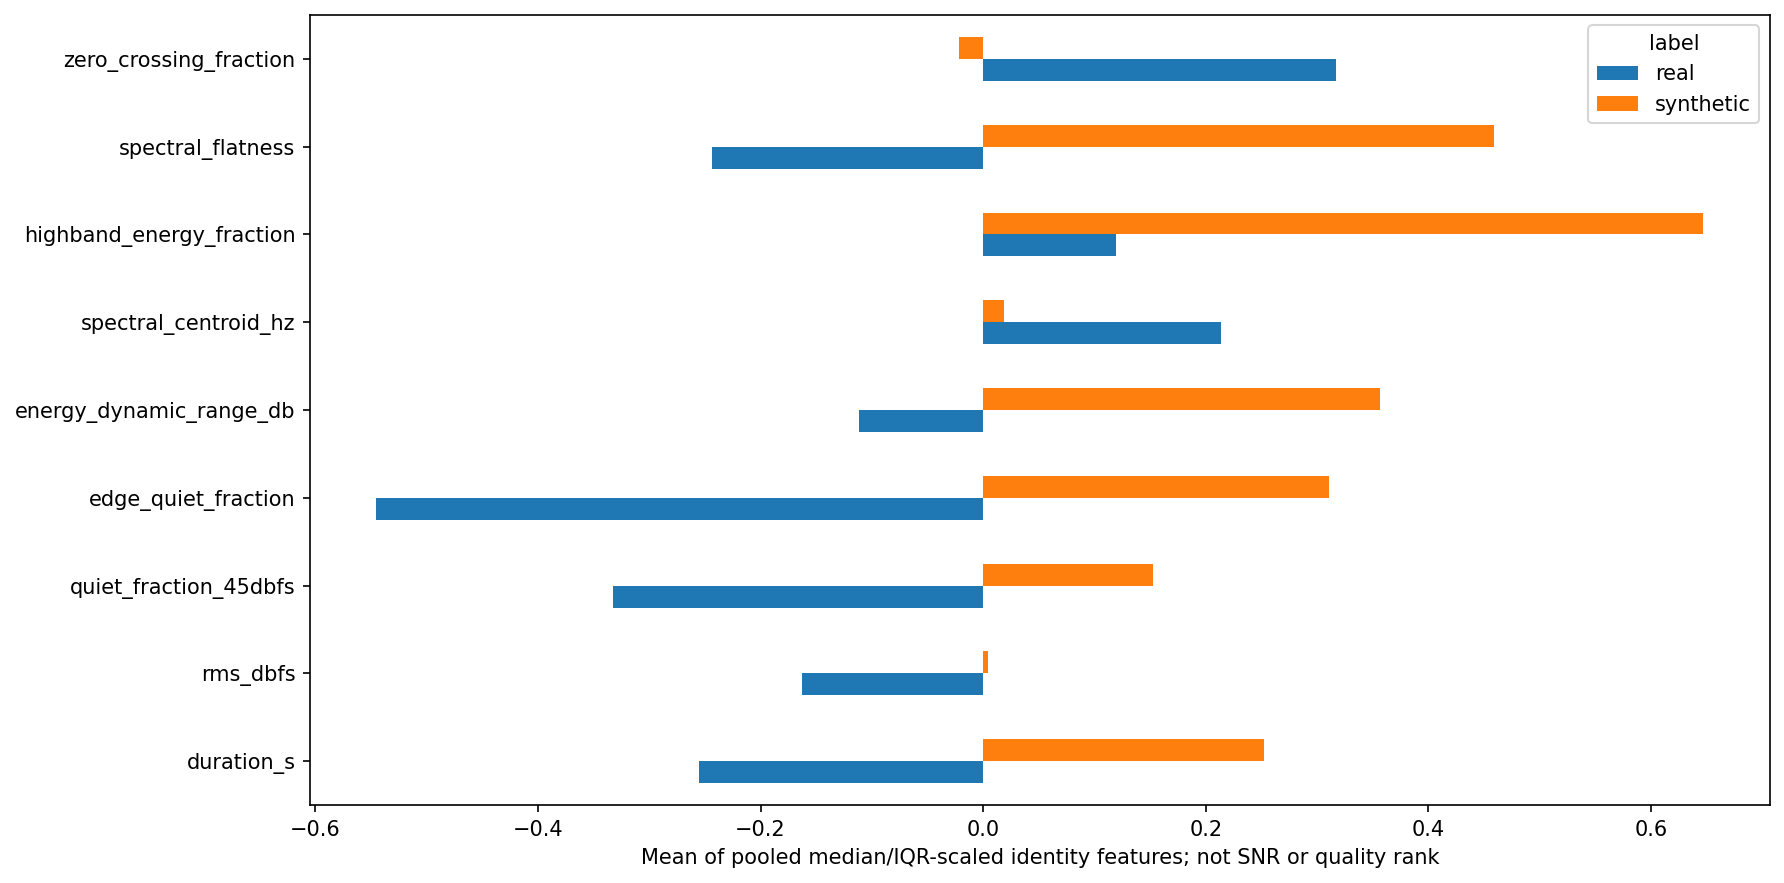

{'seed': 20261117,
 'inputs': {'voice_distribution\\samples.csv': 'f021cee8334dc01c63c9755ac0a22f7903386710ecfebf408acce2b47e6c6d3e',
  'voice_distribution\\embeddings.npz': 'a6f945e9c3b2e850fbfce704b4a94a1196d31450a66133d06e6f0dba9b4bee5e',
  'voice_distribution\\model_provenance.json': 'f13f39ceedcb91ec6ecc3d43c7f8bf6894531919cfb6486b4e7951a4e91deaa5',
  'prepare_voice_distribution.py': '53ce15070bc611581be2cd5a0ed23708b0d88560581decb97272ec624a3fbe61',
  'ecapa_embeddings.py': 'b0d079941d2d0f0649a89282fc5fd5361530bf574ad1871b3f1ce2d39049bd05',
  'analyze_voice_distributions.py': 'ae8e613f67aa26d98488a584227292f6b8fa979fb88981800f17c120436d241e',
  'VOICE_DISTRIBUTION_PLAN.md': '77f9f250b1d535bd03c4fdd592b6e43c4ba99952868238abf69eb4fcacd931fa'},
 'mmd': 'biased weighted RBF MMD squared; no significance or causal claims',
 'embedding_centroids': 'L2-normalized mean of L2 sample vectors; equal nominal identity weighting',
 'text_caution': 'all synthetic same sentence; real varied conte

Completed cached offline analysis. No TTS generation, API spend, source changes or new human ratings.


In [8]:
acoustic=table('identity_acoustic_features')
display(acoustic.groupby('label').median(numeric_only=True))
display(table('selected_acoustic_effect_sizes'))
display(table('embedding_boundary_sensitivity').groupby('label').original_trimmed_cosine.agg(['count','median','min']))
figure('acoustic_multivariate_view')
display(json.loads((OUT/'analysis_provenance.json').read_text()))
assert len(samples)==515 and samples.sample_id.is_unique
assert metrics['real_speakers']==80 and metrics['synthetic_nominal_voices']==116
print('Completed cached offline analysis. No TTS generation, API spend, source changes or new human ratings.')


Primary sources: [ECAPA-TDNN paper](https://www.isca-archive.org/interspeech_2020/desplanques20_interspeech.pdf), [official SpeechBrain checkpoint/model card](https://huggingface.co/speechbrain/spkrec-ecapa-voxceleb), [model architecture configuration](https://huggingface.co/speechbrain/spkrec-ecapa-voxceleb/blob/0f99f2d0ebe89ac095bcc5903c4dd8f72b367286/hyperparams.yaml).

Reproduce extraction/inference using the dedicated environment as described in `README_VOICE_DISTRIBUTIONS.md`. Re-execute analysis: `python build_voice_distribution_notebook.py --execute`, then `python verify_voice_distributions.py`.